# The paper's own protocol: the Table 5 fit judged on the surveys it was fitted to

**Question:** What does the in-sample protocol of the state of the art, a fit judged on the same ten surveys, say about the HP500 model, and does it separate the physics from an unconstrained fit?

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 and 02 of this topic
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- say what the state of the art on this crusher is, and what protocol it uses to judge its own model;
- run that protocol on the ten surveys with the pipeline's CrusherCal code, in sample;
- compare three models in sample, the calibrated physics, the same physics with its scalars refitted and an unconstrained regression;
- read a fitted coefficient for its physical sense, and say why a good in-sample number cannot decide between the models.

## Setup

Numpy and matplotlib. The CrusherCal functions come from the pipeline's `hp500` folder, which needs only numpy.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The cell imports the survey reader, the backbone builder and the CrusherCal builder.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, loo
from pipeline.model.crusher.capacity import throughput, HP500_QREF
from pipeline.model.crusher.hp500 import HP500_NOMINAL
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The ten surveys and the two committed documents derived from them. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten survey rows are transcribed from Table A1 of the paper. Files read: `data/examples/hp500-surveys.csv`; `data/derived/hp500/backbone.json`, the engine's results at the surveys; and `data/derived/hp500/loo.json`, the CrusherCal document (contract `hp500-loo`), kept here only to check that the live run gives it back.

The cell reads the three files.

In [2]:
# Read the surveys and the two committed documents
surveys = read_surveys().accepted
derived = ROOT / "data" / "derived" / "hp500"
committed_backbone = json.loads((derived / "backbone.json").read_text(encoding="utf-8"))
committed_loo = json.loads((derived / "loo.json").read_text(encoding="utf-8"))
print("surveys:", len(surveys), "| engine version:", committed_backbone["engine_version"])

surveys: 10 | engine version: 0.09.003


## Method

**The product's side.** The calibrated backbone is the engine's calibrated lane (notebook 02) with its published constants: the capacity base $Q_T \approx 647$ t/h and the power form $P_c = 1.30\,P_d + 110$ kW. The pipeline's CrusherCal code takes the backbone document and evaluates models of it with the same measured data. The cell rebuilds both documents live, from the surveys, and checks that they are the committed ones, so that everything below is computed here and not read.

In [3]:
# Rebuild the backbone and the CrusherCal documents live and compare them with the committed ones
version = committed_backbone["engine_version"]
live_backbone = backbone.build(surveys, version)
live_loo = loo.build(live_backbone, version)
print("backbone equals the committed one:", live_backbone == committed_backbone, "| CrusherCal equals the committed one:", live_loo == committed_loo)

backbone equals the committed one: True | CrusherCal equals the committed one: True


The protocol's own settings are module constants of the CrusherCal code: the seed of the shuffle control, the ridge penalty of the residual model and the clip that bounds the residual to a fraction of the backbone value. The cell prints them, because they define what "M1" below is.

In [4]:
# The constants of the CrusherCal protocol
print("shuffle-control seed:", loo.SEED, "| ridge penalty:", loo.RIDGE_LAMBDA, "| residual clip, fraction of the backbone:", loo.RESID_CLIP_FRAC)

shuffle-control seed: 42 | ridge penalty: 1.0 | residual clip, fraction of the backbone: 0.2


## State of the art

**The source.** The state of the art on this machine is Rocha, Campos, Silva and Tavares (2024; https://doi.org/10.3390/min14090919): a fit-for-purpose model of the HP500, with the Andersen-Whiten classification and breakage parameters, the capacity and the power, fitted to the ten surveys and judged on them. Its protocol is the usual one for such models, an in-sample fit: the constants come from the ten surveys, and the model's agreement with the same ten surveys is the evidence. The neighbouring literature on learned surrogates of comminution models has the same shape: Koh et al. (2021; https://doi.org/10.1016/j.mineng.2021.107026) judge a network against the model it emulates, not against a held-out plant.

An in-sample fit is not wrong; it answers a different question than "how will it do on the next survey". The notebook runs that protocol with the pipeline's own CrusherCal code and reads what it can say. The CrusherCal document holds, for each model, a block computed with the fit on all ten surveys (`leaky`, the in-sample variant) and a block with the survey held out (`strict`, topic 06). The cell reads the in-sample throughput blocks of three models: the calibrated backbone with the scalar $Q_T$ refitted to all ten surveys (M0), the same backbone plus a bounded ridge residual (M1), and an unconstrained linear regression on the setting and the f80 with no physics (M2), next to a constant-mean baseline.

In [5]:
# In-sample (leaky) throughput errors of the three models, the shipped backbone and the constant mean
block = live_loo["loo"]["tph"]["leaky"]
shipped = live_loo["tph_parity"]["backbone"]
rows = {
    "backbone as shipped (QT = 647 t/h)": shipped["mape_pct"],
    "M0, QT refitted to the ten": block["M0_backbone"]["mape_pct"],
    "M1, backbone plus bounded residual": block["M1_residual"]["mape_pct"],
    "M2, free-form regression": block["M2_freeform"]["mape_pct"],
    "constant mean": block["constant_mean"]["mape_pct"],
}
for name, value in rows.items():
    print(f"{name:42s} in-sample MAPE {value:6.2f} %")

backbone as shipped (QT = 647 t/h)         in-sample MAPE  11.55 %
M0, QT refitted to the ten                 in-sample MAPE  10.95 %
M1, backbone plus bounded residual         in-sample MAPE   8.51 %
M2, free-form regression                   in-sample MAPE   8.24 %
constant mean                              in-sample MAPE  16.46 %


The figure draws the five numbers. Read as the state of the art reads them, the story is favourable: the shipped calibrated backbone is inside the 15 percent band that the card for this protocol records, and it beats the constant mean. But the bar that wins is the unconstrained regression, with the physics-free model at the lowest error, and the residual model beats the backbone too. In sample, adding free parameters always helps.

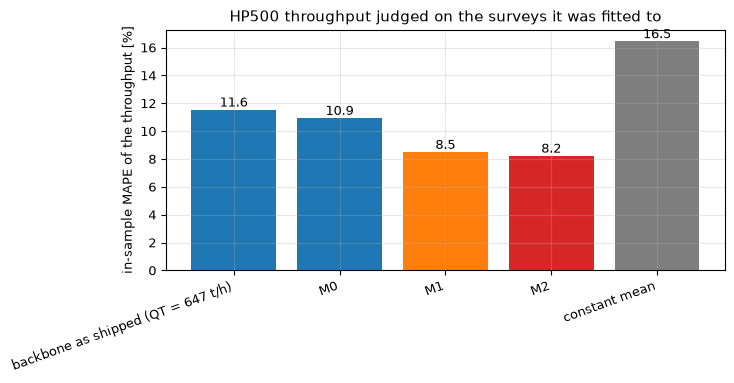

In [6]:
# Bar chart of the in-sample throughput error of the five models
labels = [name.split(",")[0] for name in rows]
fig, ax = plt.subplots()
bars = ax.bar(range(len(rows)), list(rows.values()), color=["tab:blue", "tab:blue", "tab:orange", "tab:red", "tab:grey"])
ax.bar_label(bars, fmt="%.1f")
ax.set_xticks(range(len(rows)), labels, rotation=20, ha="right")
ax.set_ylabel("in-sample MAPE of the throughput [%]")
ax.set_title("HP500 throughput judged on the surveys it was fitted to")
fig.tight_layout()
plt.show()

The ordering of the bars is the ordering of the number of free parameters, not of the quality of the physics: the regression with no physics beats the calibrated model, which cannot be what a modeller wants to conclude. The figure says that an in-sample number cannot rank these models, and it does not say how much better or worse the physics would do on a new survey. The power shows the same thing more sharply, which is the next cell: it refits the paper's power form to the Bond draw on all ten surveys and reads the coefficients.

In [7]:
# The paper's power form refitted in sample to the Bond draw: its coefficients and the errors of the power estimates
parity = live_loo["power_parity"]
refit = parity["refit_pc"]
print("refitted form Pc = zeta Pd + Pn: zeta =", refit["zeta"], "| Pn =", refit["pn"], "kW")
print("the paper's constants: zeta = 1.30, Pn = 110 kW")
for name, key in (("bare Bond draw", "bare_bond"), ("paper form on the Bond draw", "engine_pc_1p30_110"), ("form refitted in sample", "refit_pc"), ("constant mean", "constant_mean")):
    print(f"{name:44s} MAPE {parity[key]['mape_pct']:6.2f} %   R2 {parity[key]['r2']:7.3f}")

refitted form Pc = zeta Pd + Pn: zeta = -2.4146 | Pn = 828.6 kW
the paper's constants: zeta = 1.30, Pn = 110 kW
bare Bond draw                               MAPE  26.88 %   R2  -1.286
paper form on the Bond draw                  MAPE  47.58 %   R2  -3.643
form refitted in sample                      MAPE  19.28 %   R2   0.205
constant mean                                MAPE  22.03 %   R2   0.000


The refitted coefficient is $\zeta = -2.41$ with an offset of 828.6 kW: the in-sample optimum of the form is a line of negative slope, in which more Bond power predicts less measured power. The fit's 19.28 percent error beats the paper's constants on this draw (47.58 percent) and the bare Bond draw (26.88 percent), and it is a number a report could quote. It is also a physical absurdity, a negative efficiency. It arises because the Bond draw varies little (196 to 237 kW) against a measured power that spans 187 to 355 kW and is negatively correlated with it, so the regression has to tilt its line downward to follow the measured spread: it is fitting the survey-to-survey variation, not the physics. The figure plots the measured power against the Bond draw with that line.

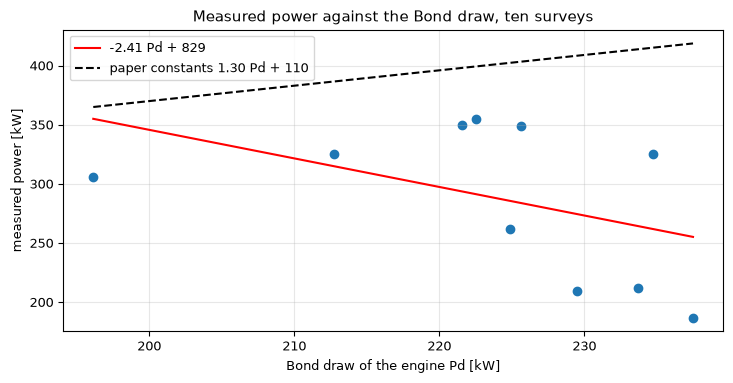

correlation of measured power with the Bond draw: -0.453


In [8]:
# Scatter of the measured power against the Bond draw with the in-sample refit line
bond = np.array([s["backbone"]["bond_power_kw"] for s in live_backbone["surveys"]])
measured_kw = np.array([s["measured"]["power_kw"] for s in live_backbone["surveys"]])
fig, ax = plt.subplots()
ax.scatter(bond, measured_kw)
line = np.linspace(bond.min(), bond.max(), 20)
ax.plot(line, refit["zeta"] * line + refit["pn"], "r-", label=f"{refit['zeta']:.2f} Pd + {refit['pn']:.0f}")
ax.plot(line, 1.30 * line + 110, "k--", label="paper constants 1.30 Pd + 110")
ax.set_xlabel("Bond draw of the engine Pd [kW]")
ax.set_ylabel("measured power [kW]")
ax.set_title("Measured power against the Bond draw, ten surveys")
ax.legend()
fig.tight_layout()
plt.show()
print("correlation of measured power with the Bond draw:", round(float(np.corrcoef(bond, measured_kw)[0, 1]), 3))

The ten points form a cloud without a clean relation: the red line tilts down through them, the black dashed line of the paper's constants lies above all of them, and the correlation printed under the figure is negative. The figure shows why an in-sample fit cannot be trusted to carry physical meaning on ten points and a flat regressor, and why the product's report keeps the measured power as the reference and does not offer the model kW as a prediction. It does not show what happens on a survey outside the ten; that needs the held-out protocol of topic 06.

**Which in-sample numbers depend on chance?** Four of the five throughput numbers are deterministic given the surveys. The label-shuffle control is the exception, because it permutes the measured values with a seeded generator. The cell rebuilds the CrusherCal document with another seed and compares the in-sample numbers of the models with those of the committed seed.

In [9]:
# Rebuild CrusherCal with seed 1 and compare the in-sample throughput errors with the committed seed
other = loo.build(live_backbone, version, seed=1)["loo"]["tph"]["leaky"]
for name in ("M0_backbone", "M1_residual", "M2_freeform", "constant_mean", "M1_label_shuffle"):
    print(f"{name:18s} seed {loo.SEED}: {block[name]['mape_pct']:6.2f} %   seed 1: {other[name]['mape_pct']:6.2f} %")

M0_backbone        seed 42:  10.95 %   seed 1:  10.95 %
M1_residual        seed 42:   8.51 %   seed 1:   8.51 %
M2_freeform        seed 42:   8.24 %   seed 1:   8.24 %
constant_mean      seed 42:  16.46 %   seed 1:  16.46 %
M1_label_shuffle   seed 42:  21.18 %   seed 1:  14.71 %


The four models do not move: their in-sample numbers belong to the data and not to the seed. Only the shuffle control changes, from 21.18 to 14.71 percent, and that spread is itself information: a control built to be worse than the physics sometimes comes out at 14.71 percent, close to the models it is meant to lose to, which warns that with ten points a single draw of the control says little. The next cell turns to the physics' own free scalar, the capacity base.

In [10]:
# Refit the capacity base QT of the backbone to the ten surveys by least squares and compare it with the paper's
shape = np.array([throughput("cone-sec", s.css_mm, HP500_NOMINAL.throw_mm, HP500_NOMINAL.speed_rpm, True) for s in surveys]) / HP500_QREF
measured = np.array([s.feed_tph for s in surveys])
qt_refit = float((shape * measured).sum() / (shape * shape).sum())
print("paper's capacity base [t/h]:", HP500_QREF, "| in-sample least-squares optimum [t/h]:", round(qt_refit, 1))

paper's capacity base [t/h]: 647 | in-sample least-squares optimum [t/h]: 686.0


The in-sample optimum of the scalar is 686.0 t/h, 6 percent above the paper's 647 t/h, and it buys the reduction of the error from 11.55 to 10.95 percent. The paper's value is not the least-squares one on these ten rows: it is the published constant, and the difference shows how much a single in-sample scalar moves the number, 0.6 points. The free-form regression with its three free coefficients moves it by 3.3 points, which is the cost in degrees of freedom of the in-sample ranking.

## Results

**Answer:** the in-sample protocol is favourable to the HP500 model and cannot tell it apart from an overfit. On throughput the in-sample errors are 11.55 percent for the shipped backbone, 10.95 for the refitted scalar, 8.51 for the bounded residual, 8.24 for the free-form regression and 16.46 for the constant mean: the ranking follows the number of free parameters, and the physics-free regression has the lowest error. On power the in-sample refit of the paper's form gives 19.28 percent, better than the paper's constants (47.58 percent) and the bare Bond draw (26.88 percent), with a negative coefficient, zeta = -2.41, that has no physical meaning.

The first figure shows the ordering by parameter count, the second the absurd coefficient on a cloud with no relation. A validator would conclude that the state of the art's protocol is sound for what it claims, a calibration, and silent on what the product wants to claim, a prediction; that the physics-free regression winning in sample is the evidence that the protocol cannot discriminate; and that the right next step is to hold each survey out in turn, which topic 06 does with the same code.

## Summary

The state of the art for this crusher fits ten surveys and judges the fit on the same ten, a protocol that favours whichever model has more freedom: here the physics-free regression and a power coefficient with the wrong sign. The pipeline's CrusherCal code runs the protocol and gives the in-sample numbers beside the held-out ones in one document. Topic 06 reads the held-out half, which is where the product's own claim sits.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Bond, F. C. (1952), The third theory of comminution, Transactions AIME 193, 484-494. https://onemine.org/documents/the-third-theory-of-comminution
- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026